# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [2]:
cell_img = plt.imread('data/cells.png')
cell_img = resize(cell_img, (256, 256))
plt.imshow(cell_img)
plt.show()

<Figure size 640x480 with 1 Axes>

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [3]:
cell_ft = np.fft.fft2(cell_img)
print(cell_ft.dtype)

complex128


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [4]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

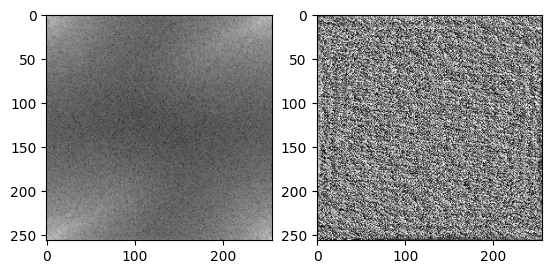

In [5]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


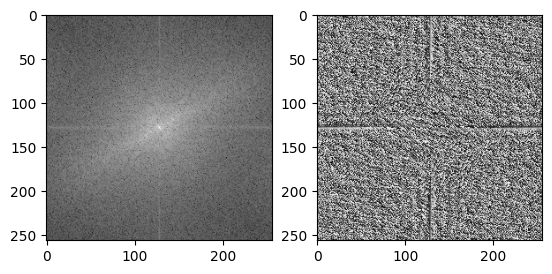

In [6]:
cell_ft_shift = np.fft.fftshift(cell_ft)
amplitude2 = np.abs(cell_ft_shift)
phase2 = np.angle(cell_ft_shift)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude2), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase2, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


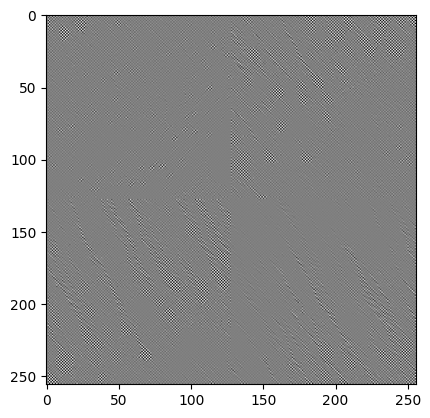

In [7]:
cell_restored = np.fft.ifft2(cell_ft_shift)
cell_restored2 = np.fft.fftshift(cell_restored)
cell_restored2 = cell_restored2.real
plt.imshow(cell_restored2, cmap= 'gray')

---


**[Task 2 (a).]()** Load the brain MR image.


In [8]:
brain = plt.imread('data/brain_mri.png')

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


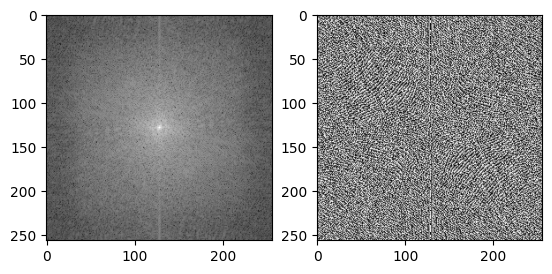

In [9]:
brain_ft = np.fft.fft2(brain)
brain_shift = np.fft.fftshift(brain_ft)
amplitude1 = np.abs(brain_shift)
phase1 = np.angle(brain_shift)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude1), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase1, 'gray')

In [10]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


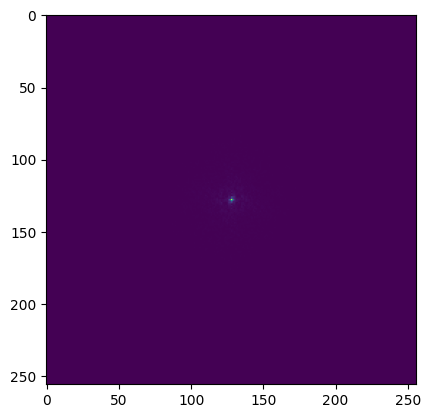

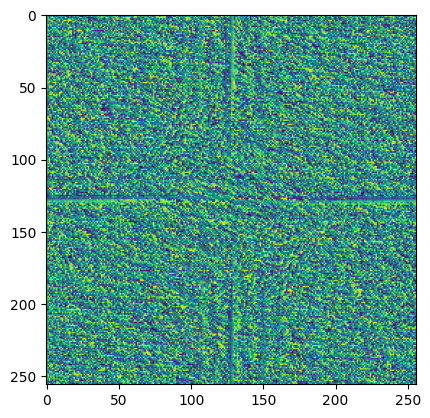

In [11]:
Merge = to_complex_array(amplitude1, phase2)

plt.imshow(np.abs(Merge))
plt.show()
plt.imshow(np.angle(Merge))
plt.show()

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


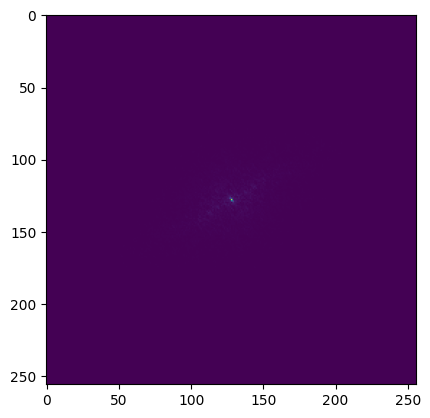

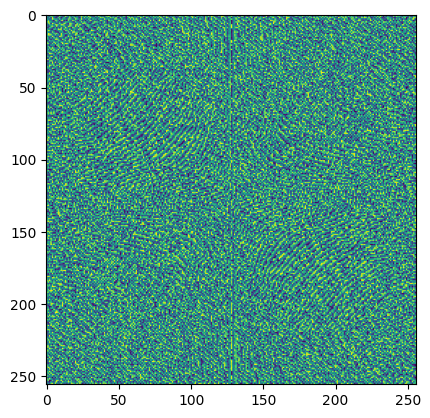

In [12]:
Merge1 = to_complex_array(amplitude2, phase1)

plt.imshow(np.abs(Merge1))
plt.show()
plt.imshow(np.angle(Merge1))
plt.show()

---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [13]:
filter_window_size = 50

In [14]:
Maske = np.zeros(amplitude2.shape)
print(Maske.astype)


<built-in method astype of numpy.ndarray object at 0x72f32c35fab0>


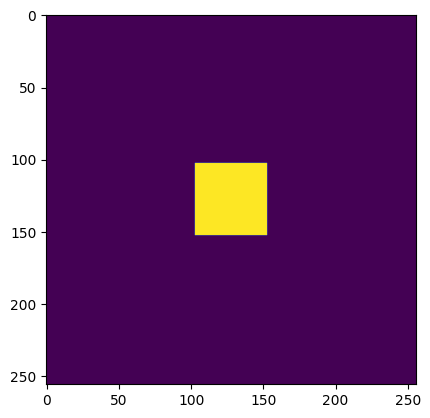

In [15]:
halfsize = filter_window_size // 2
x = Maske.shape[0] // 2
y = Maske.shape[1] // 2
xstart = x - halfsize
xend = x + halfsize
ystart = y - halfsize
yend = y + halfsize
Maske[xstart : xend, ystart : yend] = 1
plt.imshow(Maske)
plt.show()

**[Task 3 (b).]()** Create a highpass filter maks.


<function matplotlib.pyplot.show(close=None, block=None)>

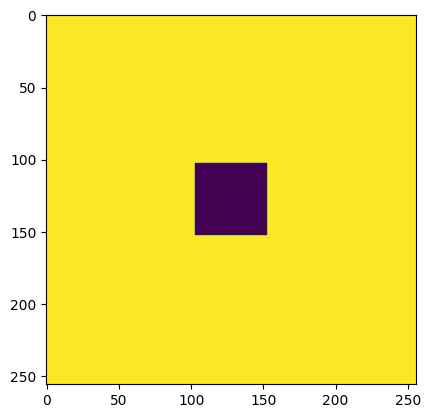

In [16]:
high = 1 - Maske
plt.imshow(high)
plt.show

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


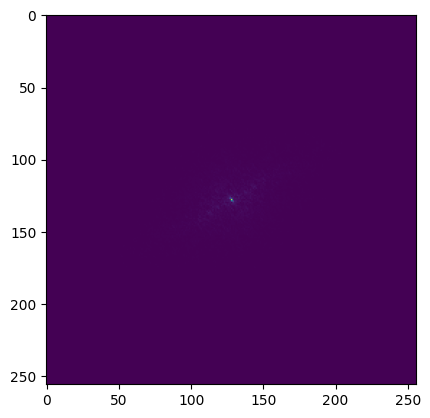

In [21]:
plt.imshow(amplitude2)
plt.show()

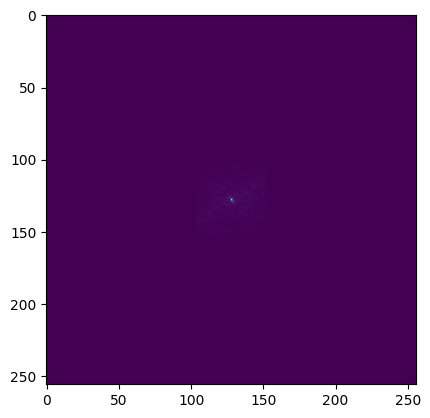

In [19]:
low_pass= amplitude2 * Maske
plt.imshow(low_pass)
plt.show()

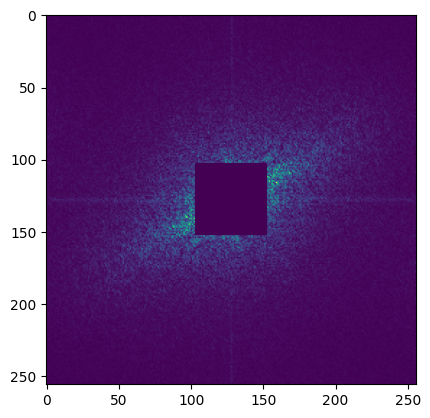

In [20]:
high_pass= amplitude2 * high
plt.imshow(high_pass)
plt.show()

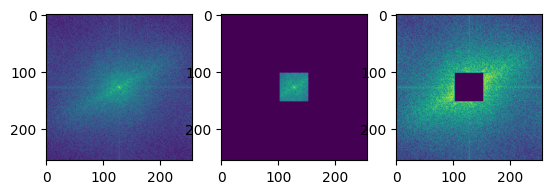

In [25]:
log_original = np.log(1 + amplitude2)
plt.subplot(1, 3, 1)
plt.imshow(log_original)

log_low = np.log(1 + low_pass)
plt.subplot(1, 3, 2)
plt.imshow(log_low)

log_high = np.log(1 + high_pass)
plt.subplot(1, 3, 3)
plt.imshow(log_high)

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


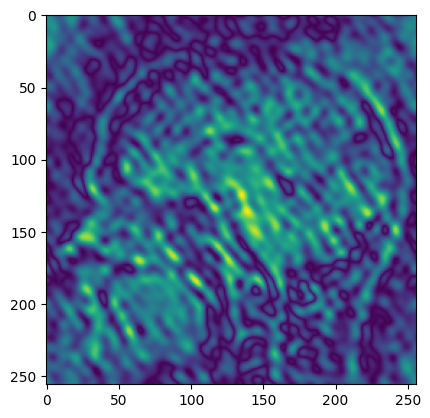

In [34]:
low_complex = to_complex_array(low_pass, phase1)
low_complex1 = np.fft.ifftshift(low_complex)
low_image = np.fft.ifft2(low_complex1)
low_image_abs = np.abs(low_image)

plt.imshow(low_image_abs)




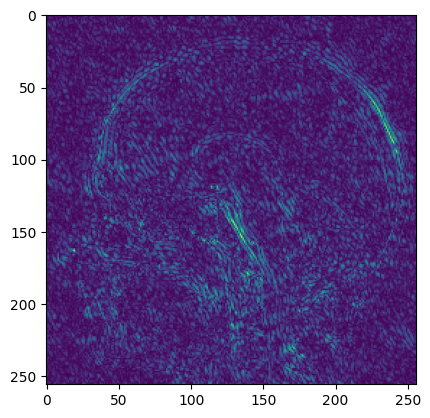

In [35]:
high_complex = to_complex_array(high_pass, phase1)
high_complex1 = np.fft.ifftshift(high_complex)
high_image = np.fft.ifft2(high_complex1)
high_image_abs = np.abs(high_image)

plt.imshow(high_image_abs)


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [62]:
def this_dft(img):
    M, N = img.shape
    dft = np.zeros((M, N), dtype = np.complex128)
    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                    dft[u, v] += img[x,y] * np.exp(-2j * np.pi * ((u * x / M) + (v * y / N)))
                    
    return dft/ (M*N)






**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [ ]:
def this_idft(img):
    M, N = img.shape
    idft = np.zeros((M, N), dtype = complex)
    for u in range(M):
        for v in range(N):
            for x in range(M):
                for y in range(N):
                    idft[u, v] += img[x,y] * np.exp(2j * np.pi * ((u * x / M) + (v * y / N)))
                    
    return idft

Due to high computational costs, we need to resize the image.


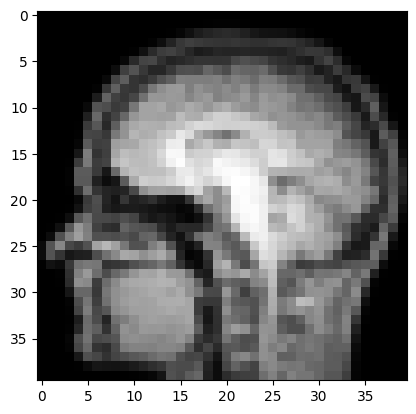

In [63]:
test_img = resize(brain, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


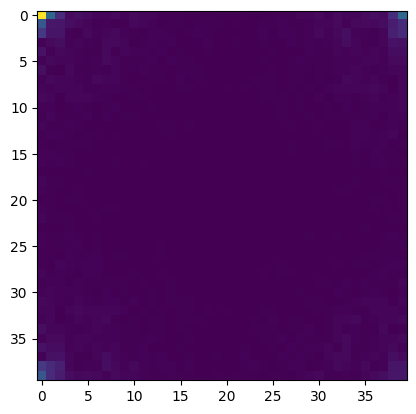

In [64]:
dft_brain = this_dft(test_img)
plt.imshow(np.abs(dft_brain))
plt.show()


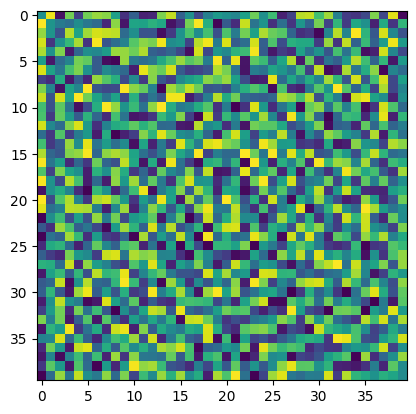

In [65]:
dft_brain2 = this_dft(test_img)
plt.imshow(np.angle(dft_brain2))
plt.show()

**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


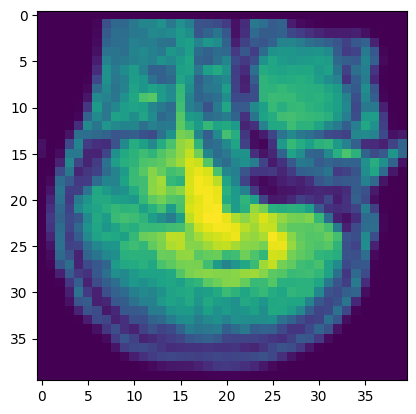

In [69]:
dft_brain3 = this_idft(dft_brain2)
plt.imshow(np.abs(dft_brain3))
plt.show()

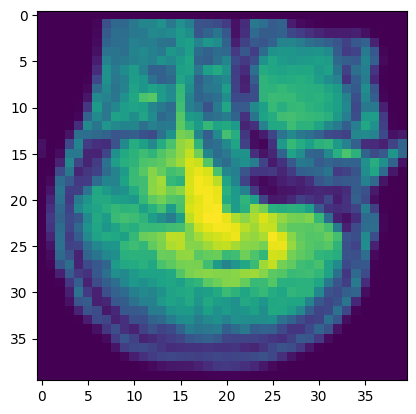

In [70]:
dft_brain4 = this_idft(dft_brain)
plt.imshow(np.abs(dft_brain4))
plt.show()

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
